## Data Preprocessing

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import librosa
from glob import glob
import IPython.display as ipd
from PIL import Image

In [2]:
# Load metadata
df = pd.read_csv("./data/bird_songs_metadata.csv/bird_songs_metadata.csv")
df.head(3)

,id,genus,species,subspecies,name,recordist,country,location,latitude,longitude,altitude,sound_type,source_url,license,time,date,remarks,filename
0,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-0.wav
1,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-1.wav
2,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-4.wav


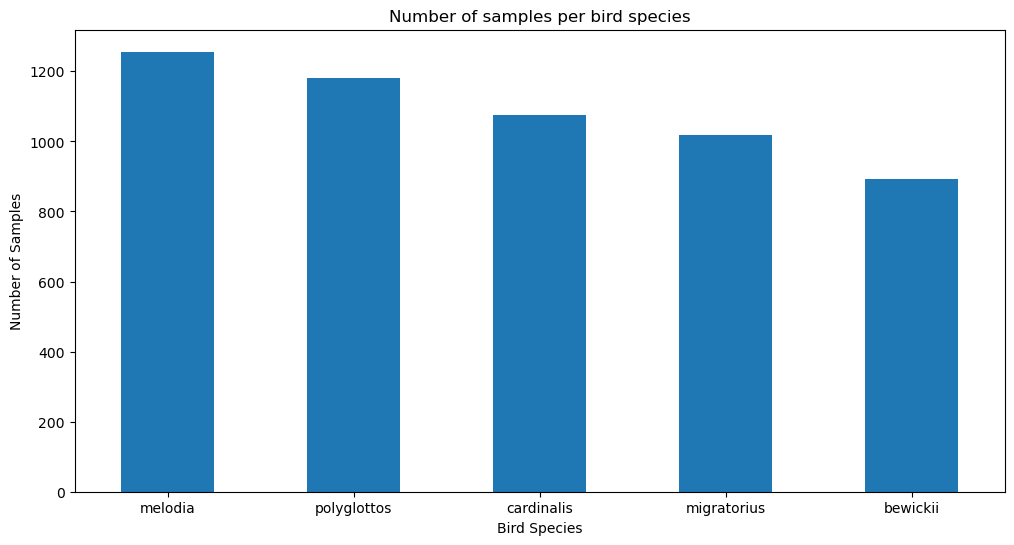

species
melodia        1256
polyglottos    1182
cardinalis     1074
migratorius    1017
bewickii        893
Name: count, dtype: int64

In [3]:
#display sample count for each bird species
plt.figure(figsize=(12,6))
df['species'].value_counts().plot(kind='bar')
plt.title('Number of samples per bird species')
plt.xlabel('Bird Species')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.show()

#get sample counts
species_counts = df['species'].value_counts()
species_counts

## Mel Spectogram

A mel pectogram is  generated from the audio files using librosa. The spectogram can be represented as an image and give us an opportunity to use the images to classify the sounds using CNN.

In [4]:
audio_files = glob('./data/wavfiles/*')
print(f"Total audio files found: {len(audio_files)}")

Total audio files found: 9107


In [5]:
#create spectogram for an audio file
def plot_spectrogram(audio_file, name):
    #load audio file
    y, sr = librosa.load(audio_file, sr=None)

    #create spectrogram
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    S_dB = librosa.power_to_db(S, ref=np.max)
    return ipd.Audio(audio_file), S_dB, sr

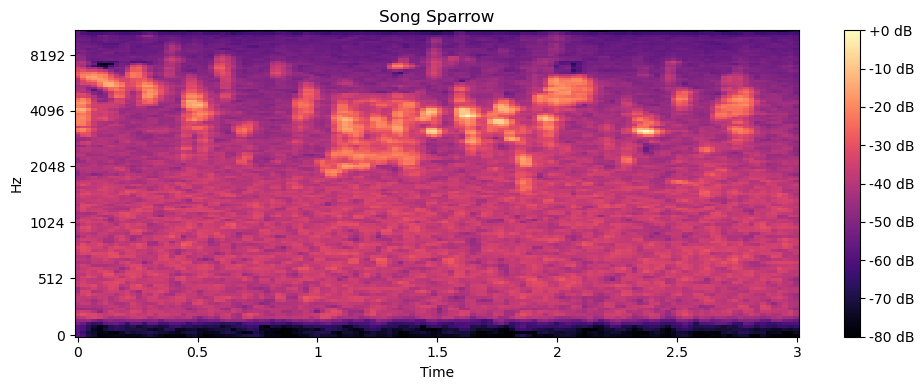

In [6]:
#display random sample spectrogram and its audio
i = np.random.randint(0, df.shape[0])
file_path = './data/wavfiles/' + df.loc[i, "filename"]
name = df.loc[i, "name"]
audio, S_db, sr = plot_spectrogram(file_path, name)
plt.figure(figsize=(10, 4))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title(name)
plt.tight_layout()
plt.show()
audio

In [7]:
# convert mel spectrogram to a resized RGB image
def mel_to_images(S_db, img_size=(128, 128)):
    # Normalize to [0, 1]
    S_norm = (S_db - S_db.min()) / (S_db.max() - S_db.min())

    # Convert to PIL image
    img = Image.fromarray((S_norm * 255).astype(np.uint8))

    # Resize
    img = img.resize(img_size, resample=Image.BILINEAR)

    # Convert to RGB
    img = img.convert("RGB")

    return np.array(img).astype(np.float32) / 255.0

print(mel_to_images(S_db).shape)

(128, 128, 3)


In [8]:
#create training dataframe with mel spectrogram images
df_train = pd.DataFrame(
    {
        "name": df["name"],
        "audio path": './data/wavfiles/' + df["filename"]
    }
)
df_train["mel_spec"] = df_train["audio path"].apply(lambda x: mel_to_images(plot_spectrogram(x, "")[1]))
df_train["class"] = df_train["name"].factorize()[0]

In [9]:
from sklearn.utils import shuffle

df_train = shuffle(df_train)
df_train.shape



(5422, 4)

In [10]:
# split data into training, validation, and test sets
(train_x, train_y) = df_train["mel_spec"].values[:4500], df_train["class"].values[:4500]
(val_x, val_y) = df_train["mel_spec"].values[4500:5000], df_train["class"].values[4500:5000]
(test_x, test_y) = df_train["mel_spec"].values[5000:], df_train["class"].values[5000:]

In [11]:
import os
os.makedirs("data/processed", exist_ok=True)

X_train = np.stack(train_x)
X_val   = np.stack(val_x)
X_test  = np.stack(test_x)

y_train = np.array(train_y)
y_val   = np.array(val_y)
y_test  = np.array(test_y)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

np.save("data/processed/X_train.npy", X_train)
np.save("data/processed/y_train.npy", y_train)

np.save("data/processed/X_val.npy", X_val)
np.save("data/processed/y_val.npy", y_val)

np.save("data/processed/X_test.npy", X_test)
np.save("data/processed/y_test.npy", y_test)

(4500, 128, 128, 3) (4500,)
(500, 128, 128, 3) (500,)
(422, 128, 128, 3) (422,)
